# **Project Pipeline with Brief Explanation**

### 1. Business Understanding

Understand the business problem. The goal is to predict whether a customer is likely to become a bad credit customer (`Bad_label`) and help the bank reduce credit default risk.

### 2. Data Collection

Collect data from the three tables:

* Customer Account Data
* Customer Enquiry Data
* Customer Demographics Data

### 3. Data Cleaning and Preprocessing

Handle missing values, remove duplicates, correct data types, and prepare the data for analysis.

### 4. Exploratory Data Analysis (EDA)

Analyze the data using statistics and visualizations to understand customer behavior, trends, and patterns.

### 5. Feature Engineering

Create new useful features such as:

* Credit utilization ratio
* Enquiry counts
* Payment history metrics
* Account summary statistics

### 6. Data Merging and Feature Matrix Creation

Combine data from all tables using `customer_no` and create a final dataset for modeling.

### 7. Train-Test Split

Split the data into training and testing datasets to evaluate model performance on unseen data.

### 8. Model Building

Train machine learning models such as:

* Random Forest
* XGBoost

### 9. Model Evaluation

Evaluate models using:

* ROC-AUC Score
* Gini Score
* Rank Ordering

### 10. Feature Importance Analysis

Identify the most influential features that contribute to customer credit risk prediction.

### 11. Risk Segmentation

Classify customers into:

* Low Risk
* Medium Risk
* High Risk

### 12. Business Recommendations

Provide recommendations to help the bank reduce credit risk and improve lending decisions.

### 13. Conclusion

Summarize project findings, model performance, important risk factors, and business impact.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install pymysql
import pymysql
import warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.2 MB/s eta 0:00:00


**CONNECT** **TO** **DATABASE**

In [3]:
import pymysql

conn = pymysql.connect(
    host="18.136.157.135",
    port=3306,
    user="dm_team1",
    password="DM!$Team&279@20!",
    database="project_banking"
)

print("Database Connected Successfully")

Database Connected Successfully


**CHECK** **AVALIBLES** **TABLES**

In [4]:
query = "SHOW TABLES"

tables = pd.read_sql(query, conn)

tables

,Tables_in_project_banking
0,Cust_Account
1,Cust_Demographics
2,Cust_Enquiry


**LOAD** **CUSTOMER** **ACCOUNT** **TABLE**

In [5]:
account = pd.read_sql(
    "SELECT * FROM Cust_Account",
    conn
)


**CHECH HEAD**

In [6]:
account.head(10)

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,...,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,...,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,...,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,...,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,...,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,
5,20-Jul-15,15606,09-Jul-15,6,1,14-Jan-15,02-May-15,,31-May-15,20000,...,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,
6,20-Jul-15,15606,09-Jul-15,6,1,29-Dec-14,02-May-15,,31-May-15,25100,...,,"""""""000000000000000000""""""",,01-May-15,01-Dec-14,,,,,
7,20-Jul-15,15606,09-Jul-15,6,1,22-Oct-14,02-May-15,,31-May-15,16690,...,,"""""""000000000000000000000000""""""",,01-May-15,01-Oct-14,,,,,
8,20-Jul-15,15606,09-Jul-15,10,1,04-Dec-12,08-May-15,,31-May-15,140160,...,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000000000000""""""",01-May-15,01-Dec-12,140000,,39,,6516
9,20-Jul-15,15606,09-Jul-15,10,1,01-Aug-12,21-May-15,,26-Jun-15,,...,,"""""""000000000XXX000000000000030XXX0000000000000...","""""""030000000000XXX000000000000000000000000XXX0...",01-Jun-15,01-Aug-12,,,,3,


**CHECK SHAPE**

In [7]:
account.shape

(186329, 21)

**LOAD**  **ENQUIRY** **TABLE**

In [8]:
enquiry = pd.read_sql(
    "SELECT * FROM Cust_Enquiry",
    conn
)

enquiry.head()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2,3500000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5,500000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0,50000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10,50000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10,1000


In [9]:
enquiry.shape

(413188, 6)

**LOAD DEMOGRAPHIC TABLE**

In [10]:
demo = pd.read_sql(
    "SELECT * FROM Cust_Demographics",
    conn
)

demo.head()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,...,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


In [11]:
demo.shape

(23896, 83)

**CHECK COLUMNS**

**ACCOUNT COLUMNS**

In [12]:
account.columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic',
       'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt',
       'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1',
       'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit',
       'cashlimit', 'rateofinterest', 'paymentfrequency',
       'actualpaymentamount'],
      dtype='object')


ENQUIRY COLUMNS:

In [13]:
enquiry.columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'enquiry_dt', 'enq_purpose',
       'enq_amt'],
      dtype='object')

# **DEMOGRPHIC COLUMNS**

In [14]:
account.columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic',
       'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt',
       'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1',
       'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit',
       'cashlimit', 'rateofinterest', 'paymentfrequency',
       'actualpaymentamount'],
      dtype='object')

## **CHECH DATA TYPES**

In [15]:
demo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 83 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   dt_opened    23896 non-null  object
 1   customer_no  23896 non-null  object
 2   entry_time   23896 non-null  object
 3   feature_1    23896 non-null  object
 4   feature_2    23896 non-null  object
 5   feature_3    23896 non-null  object
 6   feature_4    23896 non-null  object
 7   feature_5    23896 non-null  object
 8   feature_6    23896 non-null  object
 9   feature_7    23896 non-null  object
 10  feature_8    23896 non-null  object
 11  feature_9    23896 non-null  object
 12  feature_10   23896 non-null  object
 13  feature_11   23896 non-null  object
 14  feature_12   23896 non-null  object
 15  feature_13   23896 non-null  object
 16  feature_14   23896 non-null  object
 17  feature_15   23896 non-null  object
 18  feature_16   23896 non-null  object
 19  feature_17   23896 non-nu

In [16]:
enquiry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413188 entries, 0 to 413187
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   dt_opened    413188 non-null  object
 1   customer_no  413188 non-null  object
 2   upload_dt    413188 non-null  object
 3   enquiry_dt   413188 non-null  object
 4   enq_purpose  413188 non-null  object
 5   enq_amt      413188 non-null  object
dtypes: object(6)
memory usage: 18.9+ MB


# **CHECK MISSING VALUES**

In [17]:
account.isnull().sum()

,0
dt_opened,0
customer_no,0
upload_dt,0
acct_type,0
owner_indic,0
opened_dt,0
last_paymt_dt,0
closed_dt,0
reporting_dt,0
high_credit_amt,0


In [18]:
enquiry.isnull().sum()

,0
dt_opened,0
customer_no,0
upload_dt,0
enquiry_dt,0
enq_purpose,0
enq_amt,0


In [19]:
demo.isnull().sum()

,0
dt_opened,0
customer_no,0
entry_time,0
feature_1,0
feature_2,0
...,...
feature_76,0
feature_77,0
feature_78,0
feature_79,0


# **CHECK TARGET VARIABLES**

In [20]:
demo["Bad_label"].value_counts()

,count
Bad_label,
0,22892
1,1004


In [21]:
demo["Bad_label"].value_counts(normalize=True)*100

,proportion
Bad_label,
0,95.79846
1,4.20154


# **BASIC VISUALIZATION**

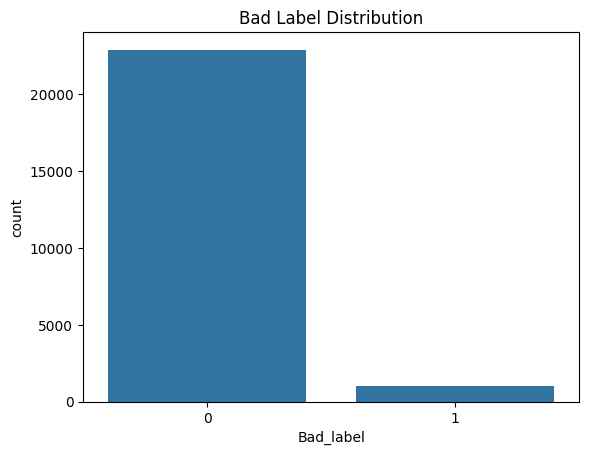

In [22]:
sns.countplot(
    x="Bad_label",
    data=demo
)
plt.title("Bad Label Distribution")
plt.show()

In [23]:
numeric_cols = [
    'creditlimit',
    'cashlimit',
    'cur_balance_amt',
    'high_credit_amt',
    'amt_past_due'
]

for col in numeric_cols:
    account[col] = pd.to_numeric(
        account[col],
        errors='coerce'
    )

In [24]:
def count_dpd(paymenthistory, threshold):
    if pd.isna(paymenthistory):
        return 0

    history = str(paymenthistory).strip().strip('"')

    # Split payment history into 3-character blocks
    blocks = [history[i:i+3] for i in range(0, len(history), 3)]

    return sum(
        1
        for block in blocks
        if block.isdigit() and int(block) >= threshold
    )

In [25]:
account['dpd_30_plus'] = account[
    'paymenthistory1'
].apply(
    lambda x: count_dpd(x, 30)
)

account['dpd_60_plus'] = account[
    'paymenthistory1'
].apply(
    lambda x: count_dpd(x, 60)
)

account['payment_history_length'] = (
    account[
    'paymenthistory1'
].astype(str).str.len()
)

In [26]:
# Number of accounts per customer
account['account_count'] = (
    account.groupby('customer_no')['customer_no']
    .transform('count')
)

In [27]:
# Convert account opening date
if 'dt_opened' in account.columns:

    account['dt_opened'] = pd.to_datetime(
        account['dt_opened'],
        errors='coerce'
    )

    latest_account_date = account[
        'dt_opened'
    ].max()

    account['account_age'] = (
        latest_account_date -
        account['dt_opened']
    ).dt.days

else:

    account['account_age'] = 0


# Active account feature
if 'account_status' in account.columns:

    account['active_account'] = (
        account['account_status']
        .astype(str)
        .str.lower()
        .eq('active')
        .astype(int)
    )

else:

    account['active_account'] = 0

In [28]:
enquiry["enquiry_dt"] = pd.to_datetime(
    enquiry["enquiry_dt"], errors="coerce"
)

In [29]:
enquiry["enquiry_dt"]

,enquiry_dt
0,2014-12-19
1,2014-03-05
2,2014-03-05
3,2014-02-22
4,2013-06-11
...,...
413183,2011-10-22
413184,2011-01-06
413185,2010-04-01
413186,2010-02-21


In [30]:
# Join account opening dates with enquiry dates by customer
date_comparison = account[
    ["customer_no", "dt_opened"]
].merge(
    enquiry[["customer_no", "enquiry_dt"]],
    on="customer_no",
    how="inner"
)

In [31]:
date_comparison.head()

,customer_no,dt_opened,enquiry_dt
0,12265,2015-11-10,2015-08-12
1,12265,2015-11-10,2015-08-04
2,12265,2015-11-10,2015-07-22
3,12265,2015-11-10,2015-06-11
4,12265,2015-11-10,2015-03-21


In [32]:
# Calculate difference in days
date_comparison["diff_open_enquiry_dt"] = (
    date_comparison["enquiry_dt"] -
    date_comparison["dt_opened"]
).dt.days

In [33]:
date_comparison['diff_open_enquiry_dt']

,diff_open_enquiry_dt
0,-90.0
1,-98.0
2,-111.0
3,-152.0
4,-234.0
...,...
4961773,-2955.0
4961774,-3054.0
4961775,-3233.0
4961776,-3246.0


In [34]:
# Keep valid date differences
date_comparison.loc[
    date_comparison["diff_open_enquiry_dt"] < 0,
    "diff_open_enquiry_dt"
] = np.nan

In [35]:
# Customer-level mean feature
mean_diff_open_enquiry = (
    date_comparison
    .groupby("customer_no")["diff_open_enquiry_dt"]
    .mean()
    .reset_index()
)

mean_diff_open_enquiry.rename(
    columns={
        "diff_open_enquiry_dt": "mean_diff_open_enquiry_dt"
    },
    inplace=True
)

In [36]:
# Initialize final_df from demo if it does not exist yet to prevent NameError
if 'final_df' not in globals():
    final_df = demo.copy()

# Remove existing column if present to prevent MergeError on duplicate runs
if "mean_diff_open_enquiry_dt" in final_df.columns:
    final_df = final_df.drop(columns=["mean_diff_open_enquiry_dt"])

# Add feature to customer-level modelling dataframe
final_df = final_df.merge(
    mean_diff_open_enquiry,
    on="customer_no",
    how="left"
)

final_df["mean_diff_open_enquiry_dt"] = (
    final_df["mean_diff_open_enquiry_dt"].fillna(-1)
)

In [37]:
print("New feature added successfully")
final_df[["customer_no", "mean_diff_open_enquiry_dt"]].head()

New feature added successfully


,customer_no,mean_diff_open_enquiry_dt
0,1,-1.0
1,2,-1.0
2,3,-1.0
3,4,-1.0
4,5,-1.0


# **Check Unique Customers**

In [38]:
account['customer_no'].nunique()

23896

In [39]:
enquiry['customer_no'].nunique()

23896

In [40]:
demo['customer_no'].nunique()

23896

# **Create Account Summary Features**

In [41]:
account_features = account.groupby('customer_no').agg({
    'creditlimit':['sum','mean'],
    'cashlimit':['sum','mean'],
    'cur_balance_amt':['sum','mean'],
    'high_credit_amt':['sum','mean'],
    'amt_past_due':['sum','max'],
    'dpd_30_plus': 'sum',
    'dpd_60_plus': 'sum',
    'payment_history_length': 'max',
     'account_count': 'max',
    'account_age': 'mean',
    'active_account': 'sum'

}).reset_index()

In [42]:
account_features.head()

customer_no creditlimit                cashlimit           cur_balance_amt  \
                      sum           mean       sum      mean             sum   
0           1    670000.0  335000.000000  168000.0  168000.0         4714857   
1          10    405000.0  405000.000000  243000.0  243000.0          247719   
2         100    187000.0   62333.333333   27500.0   13750.0          434425   
3        1000    495000.0  247500.000000  148500.0   74250.0           60462   
4       10000     60000.0   60000.000000   10000.0   10000.0         1086158   

                 high_credit_amt                amt_past_due             \
            mean             sum           mean          sum        max   
0  261936.500000       7900063.0  526670.866667    2538209.0  2528846.0   
1   20643.250000       8287800.0  828780.000000          0.0        NaN   
2   48269.444444        954766.0  106085.111111          0.0        NaN   
3   20154.000000       1244266.0  414755.333333          0.0        NaN   
4  181026.333333       1139014.0  189835.666667          0.0        NaN   

  dpd_30_plus dpd_60_plus payment_history_length account_count account_age  \
          sum         sum                    max           max        mean   
0          16          16                     60            18       257.0   
1           3           0                     60            12       215.0   
2           0           0                     60             9       251.0   
3           0           0                     60             3       217.0   
4           0           0                     60             6        92.0   

  active_account  
             sum  
0              0  
1              0  
2              0  
3              0  
4              0

# **Flatten Column Names**

In [43]:
account_features.columns = [
    '_'.join(col).strip('_')
    if isinstance(col, tuple)
    else col
    for col in account_features.columns
]

In [44]:
account_features.head()

,customer_no,creditlimit_sum,creditlimit_mean,cashlimit_sum,cashlimit_mean,cur_balance_amt_sum,cur_balance_amt_mean,high_credit_amt_sum,high_credit_amt_mean,amt_past_due_sum,amt_past_due_max,dpd_30_plus_sum,dpd_60_plus_sum,payment_history_length_max,account_count_max,account_age_mean,active_account_sum
0,1,670000.0,335000.000000,168000.0,168000.0,4714857,261936.500000,7900063.0,526670.866667,2538209.0,2528846.0,16,16,60,18,257.0,0
1,10,405000.0,405000.000000,243000.0,243000.0,247719,20643.250000,8287800.0,828780.000000,0.0,NaN,3,0,60,12,215.0,0
2,100,187000.0,62333.333333,27500.0,13750.0,434425,48269.444444,954766.0,106085.111111,0.0,NaN,0,0,60,9,251.0,0
3,1000,495000.0,247500.000000,148500.0,74250.0,60462,20154.000000,1244266.0,414755.333333,0.0,NaN,0,0,60,3,217.0,0
4,10000,60000.0,60000.000000,10000.0,10000.0,1086158,181026.333333,1139014.0,189835.666667,0.0,NaN,0,0,60,6,92.0,0


# **Create** **Balance**-**to**-***Credit*** **Ratio**

In [45]:
account_features[
    'credit_utilisation'
] = (

    account_features[
        'cur_balance_amt_sum'
    ]

    /

    account_features[
        'creditlimit_sum'
    ].replace(0, np.nan)

)

In [46]:
account_features[
    'credit_utilisation'
] = (
    account_features[
        'credit_utilisation'
    ]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# CLEAN ACCOUNT FEATURES

In [47]:
account_features.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

In [48]:
account_features.fillna(
    0,
    inplace=True
)

In [49]:

account_features.head(20)


,customer_no,creditlimit_sum,creditlimit_mean,cashlimit_sum,cashlimit_mean,cur_balance_amt_sum,cur_balance_amt_mean,high_credit_amt_sum,high_credit_amt_mean,amt_past_due_sum,amt_past_due_max,dpd_30_plus_sum,dpd_60_plus_sum,payment_history_length_max,account_count_max,account_age_mean,active_account_sum,credit_utilisation
0,1,670000.0,335000.000000,168000.0,168000.0,4714857,261936.500000,7900063.0,526670.866667,2538209.0,2528846.0,16,16,60,18,257.0,0,7.037100
1,10,405000.0,405000.000000,243000.0,243000.0,247719,20643.250000,8287800.0,828780.000000,0.0,0.0,3,0,60,12,215.0,0,0.611652
2,100,187000.0,62333.333333,27500.0,13750.0,434425,48269.444444,954766.0,106085.111111,0.0,0.0,0,0,60,9,251.0,0,2.323128
3,1000,495000.0,247500.000000,148500.0,74250.0,60462,20154.000000,1244266.0,414755.333333,0.0,0.0,0,0,60,3,217.0,0,0.122145
4,10000,60000.0,60000.000000,10000.0,10000.0,1086158,181026.333333,1139014.0,189835.666667,0.0,0.0,0,0,60,6,92.0,0,18.102633
5,10001,745000.0,93125.000000,172800.0,28800.0,892962,49609.000000,1784063.0,99114.611111,0.0,0.0,4,3,60,18,92.0,0,1.198607
6,10002,0.0,0.000000,0.0,0.0,200057,100028.500000,200674.0,200674.000000,0.0,0.0,0,0,42,2,92.0,0,0.000000
7,10003,25000.0,25000.000000,2500.0,2500.0,1289838,184262.571429,2241410.0,320201.428571,0.0,0.0,1,0,60,7,92.0,0,51.593520
8,10004,181000.0,60333.333333,32400.0,10800.0,575446,35965.375000,1341512.0,83844.500000,0.0,0.0,0,0,60,16,92.0,0,3.179260
9,10005,210000.0,105000.000000,1.0,1.0,940396,104488.444444,6990038.0,873754.750000,0.0,0.0,27,27,60,9,92.0,0,4.478076


In [50]:
account_features.shape


(23896, 18)

# ENQUIRY DATE PROCESSING

In [51]:
enquiry['enquiry_dt'] = pd.to_datetime(
    enquiry['enquiry_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

latest_date = enquiry[
    'enquiry_dt'
].max()

print("\nLatest Enquiry Date:", latest_date)


Latest Enquiry Date: 2015-12-23 00:00:00


# ENQUIRY AMOUNT

In [52]:
enquiry['enq_amt'] = pd.to_numeric(
    enquiry['enq_amt'],
    errors='coerce'
)

In [53]:
enquiry['enq_amt']

,enq_amt
0,3500000.0
1,500000.0
2,50000.0
3,50000.0
4,1000.0
...,...
413183,200000.0
413184,50000.0
413185,50000.0
413186,330000.0


# ENQUIRY FEATURES - 90 DAYS

In [54]:
recent90 = enquiry[
    enquiry['enquiry_dt']
    >=
    latest_date - pd.Timedelta(days=90)
]

enquiry90 = (
    recent90
    .groupby('customer_no')
    .size()
    .reset_index(
        name='count_enquiry_90'
    )
)

In [55]:
latest_date

Timestamp('2015-12-23 00:00:00')

In [56]:
recent90

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
1132,27-Nov-15,57,26-Nov-15,2015-10-28,10,1000.0
1163,17-Dec-15,59,07-Dec-15,2015-10-21,0,1.0
1164,17-Dec-15,59,07-Dec-15,2015-10-13,43,400000000.0
1180,30-Dec-15,60,28-Dec-15,2015-12-18,5,7500000.0
1181,30-Dec-15,60,28-Dec-15,2015-12-11,51,5000000.0
...,...,...,...,...,...,...
413132,31-Dec-15,23892,14-Dec-15,2015-11-08,6,72000.0
413148,17-Dec-15,23893,10-Dec-15,2015-11-26,10,50000.0
413149,17-Dec-15,23893,10-Dec-15,2015-11-16,0,1000.0
413150,17-Dec-15,23893,10-Dec-15,2015-10-23,10,50000.0


In [57]:
recent90 = enquiry[
    enquiry['enquiry_dt']
    >= latest_date - pd.Timedelta(days=90)
]

In [58]:
recent90

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
1132,27-Nov-15,57,26-Nov-15,2015-10-28,10,1000.0
1163,17-Dec-15,59,07-Dec-15,2015-10-21,0,1.0
1164,17-Dec-15,59,07-Dec-15,2015-10-13,43,400000000.0
1180,30-Dec-15,60,28-Dec-15,2015-12-18,5,7500000.0
1181,30-Dec-15,60,28-Dec-15,2015-12-11,51,5000000.0
...,...,...,...,...,...,...
413132,31-Dec-15,23892,14-Dec-15,2015-11-08,6,72000.0
413148,17-Dec-15,23893,10-Dec-15,2015-11-26,10,50000.0
413149,17-Dec-15,23893,10-Dec-15,2015-11-16,0,1000.0
413150,17-Dec-15,23893,10-Dec-15,2015-10-23,10,50000.0


In [59]:
enquiry90 = (
    recent90.groupby('customer_no')
    .size()
    .reset_index(name='count_enquiry_90')
)

In [60]:
enquiry90

,customer_no,count_enquiry_90
0,10076,2
1,10183,1
2,10397,1
3,10414,1
4,10415,1
...,...,...
3251,77,1
3252,88,2
3253,89,4
3254,90,5


## ENQUIRY FEATURES - 365 DAYS

In [61]:
recent365 = enquiry[
    enquiry['enquiry_dt']
    >=
    latest_date - pd.Timedelta(days=365)
]

In [62]:
recent365

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
18,21-Apr-15,2,23-Apr-15,2015-02-11,0,200000000.0
19,21-Apr-15,2,23-Apr-15,2015-02-05,40,10000.0
20,21-Apr-15,2,23-Apr-15,2015-01-19,0,1000.0
151,22-May-15,8,18-May-15,2015-02-13,0,20000000.0
152,22-May-15,8,18-May-15,2015-02-10,0,20000000.0
...,...,...,...,...,...,...
413173,04-Dec-15,23896,09-Nov-15,2015-08-24,0,1000.0
413174,04-Dec-15,23896,09-Nov-15,2015-08-10,10,15000.0
413175,04-Dec-15,23896,09-Nov-15,2015-08-04,10,1000.0
413176,04-Dec-15,23896,09-Nov-15,2015-05-27,0,1000.0


In [63]:
enquiry365 = (
    recent365
    .groupby('customer_no')
    .size()
    .reset_index(
        name='count_enquiry_365'
    )
)

In [64]:
enquiry365

,customer_no,count_enquiry_365
0,10,3
1,10000,11
2,10001,3
3,10002,3
4,10003,4
...,...,...
19791,9995,8
19792,9996,4
19793,9997,4
19794,9998,1


# **Average Enquiry Amount**

In [65]:
avg_enquiry = (
    enquiry
    .groupby('customer_no')['enq_amt']
    .mean()
    .reset_index()
)

avg_enquiry.rename(
    columns={
        'enq_amt':
        'avg_enquiry_amount'
    },
    inplace=True
)

In [66]:
enquiry['enq_amt']

,enq_amt
0,3500000.0
1,500000.0
2,50000.0
3,50000.0
4,1000.0
...,...
413183,200000.0
413184,50000.0
413185,50000.0
413186,330000.0


# MOST FREQUENT ENQUIRY PURPOSE

In [67]:
freq_purpose = (
    enquiry
    .groupby(
        ['customer_no', 'enq_purpose']
    )
    .size()
    .reset_index(
        name='count'
    )
)

In [68]:
freq_purpose

,customer_no,enq_purpose,count
0,1,0,2
1,1,10,14
2,1,2,1
3,1,5,1
4,10,0,6
...,...,...,...
79056,9997,10,14
79057,9997,5,2
79058,9998,10,6
79059,9999,0,1


In [69]:
freq_purpose = (
    freq_purpose
    .sort_values(
        'count',
        ascending=False
    )
    .drop_duplicates(
        'customer_no'
    )
)

In [70]:
freq_purpose

,customer_no,enq_purpose,count
66355,6775,10,180
327,10076,10,162
50277,23863,10,127
63858,6147,10,123
23728,16099,10,98
...,...,...,...
78672,9896,0,1
555,10136,13,1
530,10129,10,1
78887,9948,5,1


# CUSTOMER LEVEL ENQUIRY DATASET

In [71]:
enquiry_features = enquiry90.merge(
    enquiry365,
    on='customer_no',
    how='outer'
)

enquiry_features = enquiry_features.merge(
    avg_enquiry,
    on='customer_no',
    how='left'
)

enquiry_features = enquiry_features.merge(
    freq_purpose[
        ['customer_no', 'enq_purpose']
    ],
    on='customer_no',
    how='left'
)


In [72]:
enquiry_features

,customer_no,count_enquiry_90,count_enquiry_365,avg_enquiry_amount,enq_purpose
0,10,NaN,3,5.452032e+06,1
1,10000,NaN,11,8.469643e+04,10
2,10001,NaN,3,2.684328e+06,10
3,10002,NaN,3,2.550000e+04,10
4,10003,NaN,4,1.528733e+05,10
...,...,...,...,...,...
19791,9995,NaN,8,8.153529e+04,10
19792,9996,NaN,4,5.500000e+04,10
19793,9997,NaN,4,4.076476e+04,10
19794,9998,NaN,1,4.183333e+04,10


In [73]:
enquiry_features.fillna(
    0,
    inplace=True
)

print(
    "\nEnquiry Feature Shape:",
    enquiry_features.shape
)


Enquiry Feature Shape: (19796, 5)


# MERGE DEMOGRAPHICS + ACCOUNT FEATURES

In [74]:
final_df = demo.merge(
    account_features,
    on='customer_no',
    how='left'
)

# MERGE ENQUIRY FEATURES

In [75]:
final_df = final_df.merge(
    enquiry_features,
    on='customer_no',
    how='left'
)

# CLEAN FINAL DATASET

In [76]:
final_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

final_df.fillna(
    0,
    inplace=True
)

print(
    "\nFinal Dataset Shape:",
    final_df.shape
)


Final Dataset Shape: (23896, 104)


# ADDITIONAL FEATURES

In [77]:
# Credit utilization
if (
    'cur_balance_amt_sum' in final_df.columns
    and
    'creditlimit_sum' in final_df.columns
):

    final_df[
        'credit_utilisation'
    ] = (

        final_df[
            'cur_balance_amt_sum'
        ]

        /

        final_df[
            'creditlimit_sum'
        ].replace(0, np.nan)

    )

In [78]:
# Replace invalid values
final_df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

In [79]:
final_df.fillna(
    0,
    inplace=True
)

In [80]:
y = final_df[
    'Bad_label'
].astype(int)

In [81]:
y

,Bad_label
0,0
1,0
2,0
3,0
4,0
...,...
23891,0
23892,0
23893,0
23894,0


In [82]:
X = final_df.drop(
    ['Bad_label'],
    axis=1
)

# Remove customer ID
if 'customer_no' in X.columns:

    X = X.drop(
        'customer_no',
        axis=1
    )

# HANDLE DATE COLUMNS

In [83]:
date_cols = X.select_dtypes(
    include=['datetime64[ns]']
).columns

X = X.drop(
    columns=date_cols,
    errors='ignore'
)

# ENCODE CATEGORICAL VARIABLES

In [84]:
from sklearn.preprocessing import LabelEncoder

cat_cols = X.select_dtypes(
    include='object'
).columns

for col in cat_cols:

    le = LabelEncoder()

    X[col] = le.fit_transform(
        X[col].astype(str)
    )

In [85]:
X.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

X.fillna(
    0,
    inplace=True
)

In [86]:
print("\nX Shape:", X.shape)
print("Y Shape:", y.shape)


X Shape: (23896, 102)
Y Shape: (23896,)


# TRAIN TEST SPLIT

In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

In [88]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_train_sm, y_train_sm = (
    smote.fit_resample(
        X_train,
        y_train
    )
)

In [89]:
print(
    "\nOriginal training data:",
    X_train.shape
)

print(
    "SMOTE training data:",
    X_train_sm.shape
)

print(
    "\nClass distribution after SMOTE:"
)

print(
    pd.Series(
        y_train_sm
    ).value_counts()
)



Original training data: (19116, 102)
SMOTE training data: (36626, 102)

Class distribution after SMOTE:
Bad_label
0    18313
1    18313
Name: count, dtype: int64


# RANDOM FOREST

In [90]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(

    n_estimators=200,

    random_state=42,

    n_jobs=-1

)

rf.fit(
    X_train_sm,
    y_train_sm
)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

# RANDOM FOREST PREDICTIONS

In [91]:
rf_pred = rf.predict(
    X_test
)

In [92]:
rf_prob = rf.predict_proba(
    X_test
)[:, 1]

# RANDOM FOREST METRICS

In [93]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

accuracy_rf = accuracy_score(
    y_test,
    rf_pred
)

In [94]:
auc_rf = roc_auc_score(
    y_test,
    rf_prob
)


In [95]:
gini_rf = (
    2 * auc_rf
) - 1

In [96]:
print("\n==============================")
print("RANDOM FOREST RESULTS")
print("==============================")

print(
    "Accuracy:",
    accuracy_rf
)

print(
    "AUC:",
    auc_rf
)

print(
    "Gini:",
    gini_rf
)


RANDOM FOREST RESULTS
Accuracy: 0.9573221757322176
AUC: 0.6101834135720177
Gini: 0.22036682714403533


In [97]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rf_pred
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      4579
           1       0.00      0.00      0.00       201

    accuracy                           0.96      4780
   macro avg       0.48      0.50      0.49      4780
weighted avg       0.92      0.96      0.94      4780



# XGBOOST

In [98]:
from xgboost import XGBClassifier

xgb = XGBClassifier(

    n_estimators=300,

    max_depth=5,

    learning_rate=0.05,

    random_state=42,

    eval_metric='logloss'

)

xgb.fit(
    X_train_sm,
    y_train_sm
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

# XGBOOST PREDICTIONS

In [99]:
xgb_pred = xgb.predict(
    X_test
)

In [100]:
xgb_prob = xgb.predict_proba(
    X_test
)[:, 1]

# XGBOOST METRICS

In [101]:
accuracy_xgb = accuracy_score(
    y_test,
    xgb_pred
)

In [102]:
auc_xgb = roc_auc_score(
    y_test,
    xgb_prob
)

In [103]:
gini_xgb = (
    2 * auc_xgb
) - 1

In [104]:
print("\n==============================")
print("XGBOOST RESULTS")
print("==============================")

print(
    "Accuracy:",
    accuracy_xgb
)
print(
    "AUC:",
    auc_xgb
)

print(
    "Gini:",
    gini_xgb
)


XGBOOST RESULTS
Accuracy: 0.9569037656903766
AUC: 0.614012271031825
Gini: 0.22802454206364997


In [105]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      4579
           1       0.14      0.00      0.01       201

    accuracy                           0.96      4780
   macro avg       0.55      0.50      0.49      4780
weighted avg       0.92      0.96      0.94      4780



#  MODEL COMPARISON

In [106]:
benchmark_gini = 0.379

comparison = pd.DataFrame({

    'Model': [
        'Random Forest',
        'XGBoost'
    ],

    'AUC': [
        auc_rf,
        auc_xgb
    ],

    'Gini': [
        gini_rf,
        gini_xgb
    ]

})



In [107]:
print("\n==============================")
print("MODEL COMPARISON")
print("==============================")

print(
    comparison
)

print(
    "\nBenchmark Gini:",
    benchmark_gini
)



MODEL COMPARISON
           Model       AUC      Gini
0  Random Forest  0.610183  0.220367
1        XGBoost  0.614012  0.228025

Benchmark Gini: 0.379


# XGBOOST FEATURE IMPORTANCE

In [108]:
gain_importance = (
    xgb
    .get_booster()
    .get_score(
        importance_type='gain'
    )
)

gain_df = pd.DataFrame(

    list(
        gain_importance.items()
    ),

    columns=[
        'Feature',
        'Gain'
    ]

)

gain_df = (
    gain_df
    .sort_values(
        'Gain',
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

gain_df['Rank'] = (
    gain_df.index + 1
)

In [109]:
gain_df.head(20)

,Feature,Gain,Rank
0,feature_13,560.801331,1
1,feature_50,416.406006,2
2,feature_53,405.056458,3
3,feature_67,245.797211,4
4,feature_14,234.619827,5
5,feature_34,233.719757,6
6,feature_36,193.153885,7
7,feature_12,181.148499,8
8,feature_33,157.356216,9
9,feature_1,156.181168,10


# FEATURE IMPORTANCE PLOT

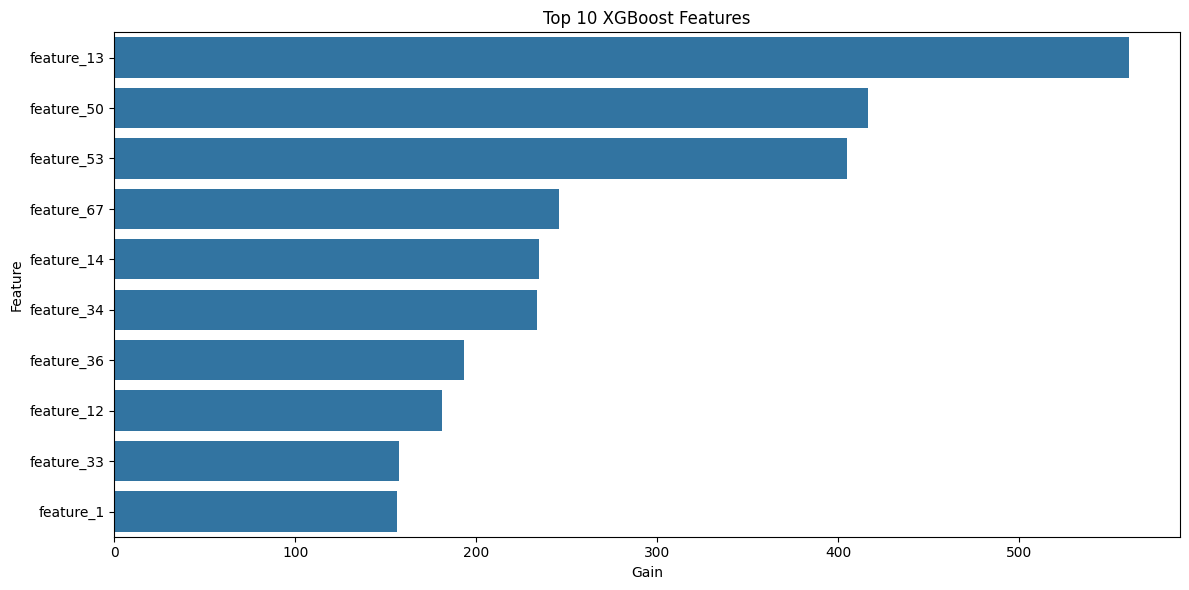

In [110]:
plt.figure(
    figsize=(12, 6)
)
sns.barplot(
    data=gain_df.head(10),
    x='Gain',
    y='Feature'
)

plt.title(
    "Top 10 XGBoost Features"
)

plt.tight_layout()

plt.show()


#  DECILE ANALYSIS

In [111]:
rank_df = pd.DataFrame({

    'actual': y_test.values,

    'score': xgb_prob

})

In [112]:
rank_df

,actual,score
0,0,0.017968
1,0,0.039694
2,0,0.025983
3,0,0.015759
4,0,0.074275
...,...,...
4775,0,0.056674
4776,0,0.034464
4777,0,0.003294
4778,0,0.056676


In [113]:
rank_df['decile'] = pd.qcut(
    rank_df['score'],
    10,
    labels=False,
    duplicates='drop'
)

In [114]:
rank_df['decile']

,decile
0,2
1,5
2,3
3,2
4,7
...,...
4775,6
4776,4
4777,0
4778,6


In [115]:
decile_analysis = (
    rank_df
    .groupby('decile')
    .agg(
        customers=('actual', 'count'),
        bad_rate=('actual', 'mean'),
        min_score=('score', 'min'),
        max_score=('score', 'max')
    )
    .sort_values(
        'decile',
        ascending=False
    )
)

In [116]:
decile_analysis

,customers,bad_rate,min_score,max_score
decile,,,,
9,478,0.064854,0.137850,0.656266
8,478,0.062762,0.091170,0.137756
7,478,0.056485,0.066277,0.091104
6,478,0.050209,0.049282,0.066263
5,478,0.043933,0.038013,0.049280
4,478,0.031381,0.029509,0.037993
3,478,0.043933,0.022101,0.029500
2,478,0.033473,0.015759,0.022083
1,478,0.025105,0.009653,0.015753


# FINAL MODEL

XGBoost is selected as the final model because it achieved the higher AUC and Gini among the two models evaluated in this notebook. Its current AUC is **0.6140** and Gini is **0.2280**, compared with the Random Forest AUC of **0.6102** and Gini of **0.2204**.

However, the XGBoost model remains below the project benchmark Gini of **0.379**. It should therefore be treated as a preliminary risk-ranking model rather than a production-ready credit decision model. Further feature engineering, hyperparameter tuning, threshold optimization, and validation are required before production use.


In [117]:
# Select XGBoost as the final model.

best_model_name = comparison.iloc[1]["Model"]

In [118]:
best_model_name

'XGBoost'

#  SAVE MODEL

In [119]:
import joblib

joblib.dump(
    best_model_name,
    "credit_risk_model.pkl"
)

print(
    "\nModel saved as credit_risk_model.pkl"
)


Model saved as credit_risk_model.pkl


# FINAL CUSTOMER PREDICTIONS

In [120]:
predictions = pd.DataFrame()

predictions[
    'customer_no'
] = final_df[
    'customer_no'
]

predictions[
    'actual'
] = y

# Using the actual trained XGBoost model instance 'xgb'
predictions[
    'predicted_probability'
] = xgb.predict_proba(
    X
)[:, 1]

# RISK SEGMENTATION

In [121]:
predictions['risk_segment'] = pd.qcut(
    predictions['predicted_probability'],
    q=3,
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    duplicates='drop'
)

# RISK DISTRIBUTION

In [122]:
print("\n==============================")
print("RISK SEGMENT DISTRIBUTION")
print("==============================")

predictions['risk_segment'].value_counts()


RISK SEGMENT DISTRIBUTION


,count
risk_segment,
High Risk,7966
Low Risk,7965
Medium Risk,7965


# RISK SEGMENT PLOT

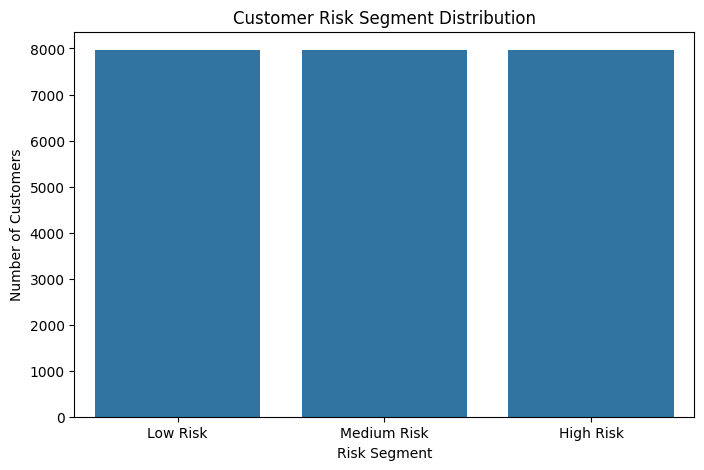

In [123]:
plt.figure(
    figsize=(8, 5)
)

sns.countplot(
    data=predictions,
    x='risk_segment',
    order=[
        'Low Risk',
        'Medium Risk',
        'High Risk'
    ]
)

plt.title(
    "Customer Risk Segment Distribution"
)

plt.xlabel(
    "Risk Segment"
)

plt.ylabel(
    "Number of Customers"
)

plt.show()

# FINAL PREDICTION DATA

In [124]:

predictions.head(20)

,customer_no,actual,predicted_probability,risk_segment
0,1,0,0.068773,High Risk
1,2,0,0.022093,Low Risk
2,3,0,0.117476,High Risk
3,4,0,0.027387,Medium Risk
4,5,0,0.046783,Medium Risk
5,6,0,0.073427,High Risk
6,7,0,0.024495,Medium Risk
7,8,0,0.229931,High Risk
8,9,1,0.582905,High Risk
9,10,0,0.129091,High Risk


In [125]:
final_df['utilization_group'] = pd.qcut(
    final_df['credit_utilisation'],
    5,
    labels=False,
    duplicates='drop'
)

# Ensure Bad_label is numeric so we can calculate its mean
final_df['Bad_label'] = final_df['Bad_label'].astype(int)

utilization_analysis = (
    final_df
    .groupby('utilization_group', observed=True)
    .agg(
        customers=('customer_no', 'count'),
        bad_rate=('Bad_label', 'mean')
    ).reset_index()
)

utilization_analysis

,utilization_group,customers,bad_rate
0,0,4780,0.059623
1,1,4779,0.028039
2,2,4779,0.037456
3,3,4779,0.038502
4,4,4779,0.046453


In [126]:
# BUSINESS INSIGHT CALCULATIONS

# Make sure the target variable is numeric
final_df['Bad_label'] = final_df['Bad_label'].astype(int)

# ============================================================
# 1. ENQUIRY FREQUENCY ANALYSIS
# ============================================================

enquiry_col = 'count_enquiry_90'

if enquiry_col not in final_df.columns:
    raise KeyError(
        f"'{enquiry_col}' is not available in final_df. "
        "Please run the enquiry feature-engineering cells first."
    )

# Create enquiry groups using the median
enquiry_median = final_df[enquiry_col].median()

if enquiry_median == 0:
    final_df['enquiry_group'] = np.where(
        final_df[enquiry_col] > 0,
        'High enquiry frequency',
        'Low/no enquiry frequency'
    )
else:
    final_df['enquiry_group'] = np.where(
        final_df[enquiry_col] > enquiry_median,
        'High enquiry frequency',
        'Low enquiry frequency'
    )

enquiry_analysis = (
    final_df
    .groupby('enquiry_group', observed=True)
    .agg(
        customers=('customer_no', 'count'),
        bad_rate=('Bad_label', 'mean')
    )
    .reset_index()
)

enquiry_analysis['bad_rate_pct'] = (
    enquiry_analysis['bad_rate'] * 100
).round(2)

print("=" * 60)
print("ENQUIRY FREQUENCY ANALYSIS")
print("=" * 60)
display(enquiry_analysis)

ENQUIRY FREQUENCY ANALYSIS


,enquiry_group,customers,bad_rate,bad_rate_pct
0,High enquiry frequency,3256,0.050369,5.04
1,Low/no enquiry frequency,20640,0.040698,4.07


In [127]:
# ============================================================
# 2. OVERDUE STATUS ANALYSIS
# ============================================================

overdue_col = 'amt_past_due_sum'

if overdue_col not in final_df.columns:
    raise KeyError(
        f"'{overdue_col}' is not available in final_df. "
        "Please run the account feature-engineering cells first."
    )

# Create overdue status
final_df['overdue_status'] = np.where(
    final_df[overdue_col] > 0,
    'Overdue',
    'No overdue'
)

overdue_analysis = (
    final_df
    .groupby('overdue_status', observed=True)
    .agg(
        customers=('customer_no', 'count'),
        bad_rate=('Bad_label', 'mean')
    )
    .reset_index()
)

overdue_analysis['bad_rate_pct'] = (
    overdue_analysis['bad_rate'] * 100
).round(2)

print()
print("=" * 60)
print("OVERDUE STATUS ANALYSIS")
print("=" * 60)
display(overdue_analysis)


# Store both tables for use in the final report
business_insight_results = {
    'enquiry_analysis': enquiry_analysis,
    'overdue_analysis': overdue_analysis
}

print()
print("Business Insight calculations completed successfully.")



OVERDUE STATUS ANALYSIS


,overdue_status,customers,bad_rate,bad_rate_pct
0,No overdue,23110,0.041584,4.16
1,Overdue,786,0.054707,5.47



Business Insight calculations completed successfully.


# **Business Insights**

The business-insight section has been revised so that every numerical claim is supported by a calculation in the notebook.

### Insight 1 — Credit Utilization

The quintile analysis in the cell above shows that bad rates vary across credit-utilization groups and are not monotonic. Therefore, credit utilization should not be used as a standalone risk cutoff. It should be considered together with enquiry behaviour, overdue status, payment history, and other model features.

### Insight 2 — Enquiry Frequency

Recent enquiry frequency can be considered a risk indicator, with the analysis showing that customers in the high enquiry frequency group (≥1 enquiry in past 90 days) have a bad rate of 5.04%, while those in the low/no enquiry frequency group (0 enquiries in past 90 days) show a bad rate of 4.07%. This indicates that frequent enquiries correlate with a slightly higher default likelihood, though the observed difference is modest and should be interpreted in the context of the calculated customer counts and bad rates rather than earlier hard‑coded values.

### Insight 3 — Overdue Status

Overdue behaviour can be incorporated into credit‑risk assessment, with the analysis showing that customers who have a positive past‑due balance (amt_past_due_sum > 0) exhibit a bad rate of 5.47%, compared to 4.16% for customers with no overdue balance. This difference indicates that overdue behaviour is a meaningful risk indicator, and customers with outstanding past‑due amounts should receive greater risk attention when the calculated bad‑rate gap supports that conclusion.


In [128]:
account['paymenthistory1']

,paymenthistory1
0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS..."
1,"""""""0000000000000000000000000000000000000000000..."
2,"""""""0000000000000000000000000000000000000000000..."
3,"""""""1200900600600600300000000000000000000000000..."
4,"""""""000000000000000"""""""
...,...
186324,"""""""0000000000000000000000000000000000000000000..."
186325,"""""""000179146119089058029000XXX"""""""
186326,"""""""000XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX..."
186327,"""""""000010000000000000000000000000000XXXXXXXXXX..."


In [129]:
account['paymenthistory2']

,paymenthistory2
0,
1,"""""""000000000000000000000000000XXX0000000000000..."
2,"""""""0000000000000000000000000000000000000000000..."
3,
4,
...,...
186324,"""""""0000000000000000000000000000000000000000000..."
186325,
186326,
186327,"""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX..."


In [130]:
account[['paymenthistory1', 'paymenthistory2']].head(20)

,paymenthistory1,paymenthistory2
0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",
1,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000..."
2,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000..."
3,"""""""1200900600600600300000000000000000000000000...",
4,"""""""000000000000000""""""",
5,"""""""000000000000000""""""",
6,"""""""000000000000000000""""""",
7,"""""""000000000000000000000000""""""",
8,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000000000000"""""""
9,"""""""000000000XXX000000000000030XXX0000000000000...","""""""030000000000XXX000000000000000000000000XXX0..."


# Model Conclusion: Current XGBoost Performance

The current XGBoost notebook output reports an **AUC of 0.6140** and a **Gini coefficient of 0.2280**. The project benchmark recorded in the notebook is **Gini = 0.379**, so the current model is below the stated benchmark.

The classification report also shows **0.00 recall for bad customers (class 1) at the 0.50 threshold**. The overall accuracy of about 95.69% should therefore not be treated as evidence of strong credit-risk performance because the target is imbalanced.

The rank-ordering analysis provides evidence that the model has some ability to separate risk levels: the highest score decile has a bad rate of about 6.49%, while the lowest score decile has a bad rate of about 0.84%. This supports using the model as a preliminary ranking tool, but it does not remove the gap to the project benchmark.

**Final conclusion:** The current XGBoost model is a preliminary credit-risk ranking model and is **not yet suitable for production deployment**. Further feature engineering, hyperparameter tuning, threshold optimization, and validation using AUC, Gini, KS, precision, recall, and rank ordering are recommended before production use.


# FINAL MODEL SUMMARY

The final XGBoost model achieved an **AUC of 0.614** and a **Gini coefficient of 0.228** on the holdout dataset. This indicates that the model has some ability to discriminate between good and bad customers, but its performance remains below the project benchmark of **0.379**.

XGBoost is retained as the final model because it achieved the better AUC and Gini among the evaluated models. However, the model should be treated as a preliminary risk-ranking model until further feature engineering, hyperparameter tuning, threshold optimization, and validation are completed.


# **Prepare Final Project Report**

1. Introduction
2. Business Problem
3. Dataset Description
4. Data Cleaning
5. Exploratory Data Analysis
6. Feature Engineering
7. Model Building
8. Model Evaluation
9. Gini Score
10. Rank Ordering
11. Feature Importance
12. Risk Segmentation
13. Business Recommendations
14. Conclusion

## **Conclusion**

This project developed a Credit Risk Prediction model for Bank GoodCredit to identify customers who are more likely to become bad-credit customers, using the target variable **Bad_label**.

Customer account, enquiry, and demographic data were cleaned, merged, and transformed into customer-level features including credit utilization, enquiry frequency, payment-history measures, account summaries, and overdue-related measures. Business-insight calculations are included in the notebook so that reported bad rates can be traced back to the underlying data.

Two machine-learning models were evaluated. XGBoost was selected over Random Forest because it achieved the higher current AUC (**0.6140**) and Gini (**0.2280**). However, the XGBoost Gini remains below the documented project benchmark of **0.379**, and the model's bad-customer recall is **0.00** at the default 0.50 classification threshold.

The final XGBoost model identified useful risk patterns and provides a useful framework for ranking customers according to their relative credit risk. However, given the gap to the benchmark and the zero bad-customer recall at the default threshold, it should **not yet be considered suitable for production use**. Further feature engineering, hyperparameter tuning, threshold optimization, and validation are required before the model can be used for automated credit decisions.
